In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [44]:
my_files = ["data/176529621_2026-10-14_19h51.25.312_Marcos_serial-reaction-time-task.csv",
            "data/239594784_2026-10-14_21h20.55.708_Marcos_serial-reaction-time-task.csv",
            "data/821011860_2026-10-14_21h41.51.257_Marcos_serial-reaction-time-task.csv"]


# Lê e concatena todos os arquivos CSV
data = pd.concat(
    [pd.read_csv(file) for file in my_files],
    ignore_index = True
)

data = data[data["trial_number"].notna()]
data.shape

(2709, 51)

In [45]:
# Remove linhas sem resposta correta ou resposta do participante
# Recalcula os acertos, ignorando maiúsculas/minúsculas
data['key_resp.corr'] = (
    data['corr_resp'].astype(str).str.strip().str.upper()
    == data['key_resp.keys'].astype(str).str.strip().str.upper()
).astype(int)

In [46]:
# 1. Proporção de acertos por bloco
accuracy = data.groupby('block_number')['key_resp.corr'].mean()

print("Proporção de acertos por bloco:")
print(accuracy)

Proporção de acertos por bloco:
block_number
0.0     0.957672
1.0     0.966667
2.0     0.971429
3.0     0.990476
4.0     0.985714
5.0     0.985714
6.0     0.990476
7.0     0.933333
8.0     0.971429
9.0     0.957143
10.0    0.976190
11.0    0.966667
12.0    0.976190
Name: key_resp.corr, dtype: float64


In [50]:
# Seleciona apenas as tentativas corretas
correct = data[data['key_resp.corr'] == 1]

# 2. RT mediano por bloco, considerando apenas tentativas corretas
correct['rt_ms'] = correct['key_resp.rt'] * 1000
rt_median = correct.groupby('block_number')['rt_ms'].median()

print("\nRT mediano por bloco:")
print(rt_median)


RT mediano por bloco:
block_number
0.0     382.44290
1.0     383.50310
2.0     334.27495
3.0     331.92215
4.0     316.79260
5.0     284.13860
6.0     317.40330
7.0     384.32120
8.0     382.92045
9.0     399.69560
10.0    383.75500
11.0    316.86910
12.0    266.61650
Name: rt_ms, dtype: float64


C:\Users\limap\AppData\Local\Temp\ipykernel_5468\3875751355.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  correct['rt_ms'] = correct['key_resp.rt'] * 1000


In [51]:
# 3. RT médio por bloco, considerando apenas tentativas corretas
rt_mean = correct.groupby('block_number')['rt_ms'].mean()

print("\nRT médio por bloco:")
print(rt_mean)


RT médio por bloco:
block_number
0.0     401.022862
1.0     399.623860
2.0     328.883459
3.0     310.512284
4.0     294.738771
5.0     277.483421
6.0     322.545456
7.0     409.734254
8.0     388.485497
9.0     417.466318
10.0    401.692417
11.0    318.900141
12.0    265.014004
Name: rt_ms, dtype: float64


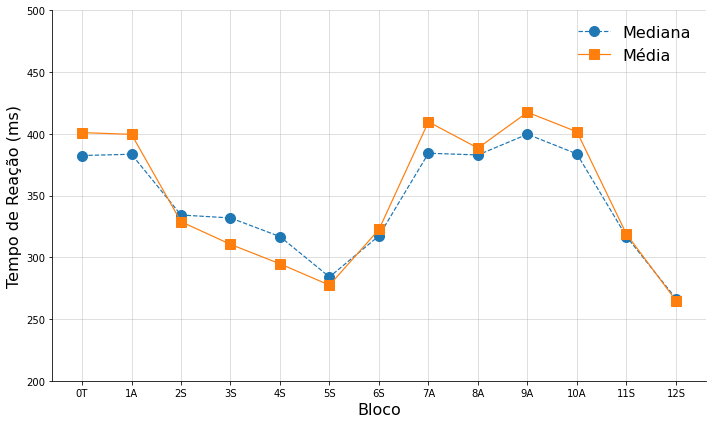

In [63]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6))


ax.plot(
    rt_median.index,
    rt_median.values,
    marker='o',
    markersize = 10,
    linestyle = "--",
    linewidth=1.2,
    label='Mediana'
)

ax.plot(
    rt_mean.index,
    rt_mean.values,
    marker='s',
    markersize = 10,
    linestyle = "-",
    linewidth=1.2,
    label='Média'
)

ax.set_xlabel('Bloco', fontsize = 16)
ax.set_xticks(sorted(data['block_number'].unique()))
ax.set_xticklabels(["0T", "1A", "2S", "3S", "4S", "5S", "6S",
                    "7A", "8A", "9A", "10A", "11S", "12S"])

ax.set_ylabel('Tempo de Reação (ms)', fontsize = 16)
ax.set_ylim(200, 500)


ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha = 0.5)

ax.legend(frameon = False, fontsize = 16, ncol = 1, loc = "upper right")
plt.tight_layout()

plt.savefig("unsworth and engle (2005), replication.jpg",
           dpi = 600,
           bbox_inches = "tight")

plt.show()

In [ ]:


# Seleciona apenas as tentativas corretas
correct = data[data['corr_resp'] == 1]


# 2. RT mediano por bloco, considerando apenas tentativas corretas
rt_median = correct.groupby('block_number')['rt'].median()

print("\nRT mediano por bloco:")
print(rt_median)


# 3. RT médio por bloco, considerando apenas tentativas corretas
rt_mean = correct.groupby('block_number')['rt'].mean()

print("\nRT médio por bloco:")
print(rt_mean)


# 4. Gráfico de linhas: RT mediano e médio por bloco
plt.figure(figsize=(8, 6), dpi=600)

plt.plot(
    rt_median.index,
    rt_median.values,
    marker='o',
    linewidth=1.2,
    label='RT mediano'
)

plt.plot(
    rt_mean.index,
    rt_mean.values,
    marker='o',
    linewidth=1.2,
    label='RT médio'
)

plt.xlabel('Bloco')
plt.ylabel('Tempo de reação (s)')
plt.xticks(sorted(data['block_number'].unique()))
plt.legend()
plt.tight_layout()
plt.show()

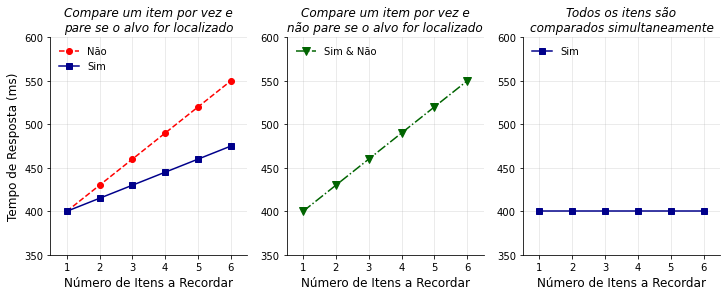

In [58]:
titles = ["Compare um item por vez e\npare se o alvo for localizado",
          "Compare um item por vez e\nnão pare se o alvo for localizado",
          "Todos os itens são\ncomparados simultaneamente"]

loads = np.array(list(range(1, 7)))

fig, axes = plt.subplots(1, 3, figsize = (12, 4))

no_responses_1 = 370 + 30 * loads
yes_responses_1 = 385 + 15 * loads

axes[0].plot(loads, no_responses_1, linestyle = "--",
             color = "red",
             marker = "o", label = "Não")
axes[0].plot(loads, yes_responses_1, linestyle = "-",
             color = "darkblue",
             marker = "s", label = "Sim")

no_responses_2 = 370 + 30 * loads
yes_responses_2 = 370 + 30 * loads

axes[1].plot(loads, no_responses_2, linestyle = "-.", 
             color = "darkgreen",
             marker = "v",
             markersize = 8,
             label = "Sim & Não")

yes_responses_3 = [400] * len(loads)

axes[2].plot(loads, yes_responses_3, linestyle = "-", 
             color = "darkblue",
             marker = "s", label = "Sim")


for i, ax in enumerate(axes):

    ax.set_title(titles[i], fontsize = 12,
                 fontstyle = "italic", color = "black")
    
    ax.set_ylim(350, 600)
    ax.set_xlim(0.5, 6.5)
    ax.set_xticks(loads)
    ax.set_xticklabels(loads)
    
    ax.set_xlabel("Número de Itens a Recordar", fontsize = 12)
    
    if i == 0:
        ax.set_ylabel("Tempo de Resposta (ms)", fontsize = 12)
    
    ax.spines[["top", "right"]].set_visible(False)
    
    ax.grid(alpha = 0.3)
    ax.legend(frameon = False, loc = "upper left")
    
plt.savefig("memory-scanning-task.jpg", dpi = 600, bbox_inches = "tight")

plt.show()

In [61]:
data = pd.read_csv(f"data/524086127_2025-12-30_11h08.46.731_Marcos Lima_alpha-span-task.csv", 
                 sep = ",")

data.shape

(146, 60)

In [62]:
data.columns

Index(['instructions.thisRepN', 'instructions.thisTrialN',
       'instructions.thisN', 'instructions.thisIndex',
       'memory_scanning_task_trials.thisRepN',
       'memory_scanning_task_trials.thisTrialN',
       'memory_scanning_task_trials.thisN',
       'memory_scanning_task_trials.thisIndex',
       'memory_scanning_task_digit.thisRepN',
       'memory_scanning_task_digit.thisTrialN',
       'memory_scanning_task_digit.thisN',
       'memory_scanning_task_digit.thisIndex', 'welcome_msg.started',
       'welcome_next.started', 'welcome_resp.started', 'participant_code',
       'instr_msg.started', 'previous.started', 'next.started',
       'instr_resp.started', 'new_trial_prompt.started',
       'new_trial_resp.started', 'to_be_remembered.started',
       'prompt_task.started', 'positive_button.started',
       'negative_button.started', 'positive.started', 'negative.started',
       'prompt_recall.started', 'resp.started', 'my_digit', 'load',
       'trial_type', 'probe', 'sequ

In [66]:
new_data = data[["load", "trial_type", "probe", "position", "resp.corr", "resp.rt"]].dropna()

rt_means = (
    new_data
    .groupby(["load", "trial_type"])["resp.rt"]
    .mean()
    .reset_index()
)

rt_means

,load,trial_type,resp.rt
0,1.0,negative,0.411771
1,1.0,positive,0.371479
2,2.0,negative,0.487035
3,2.0,positive,0.435387
4,3.0,negative,0.480660
5,3.0,positive,0.541914
6,4.0,negative,0.519998
7,4.0,positive,0.489484
8,5.0,negative,0.657733
9,5.0,positive,0.542157


In [67]:
negative = rt_means[rt_means["trial_type"] == "negative"]
positive = rt_means[rt_means["trial_type"] == "positive"]

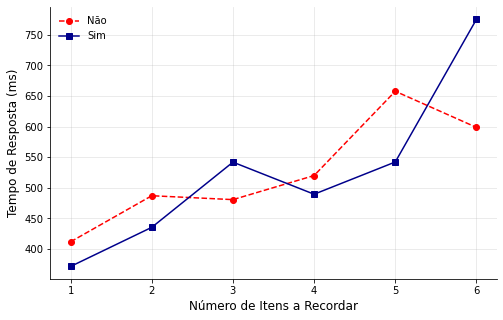

In [80]:
fig, ax = plt.subplots(1, 1, figsize = (8, 5))

ax.plot(negative["load"], negative["resp.rt"] * 1000, linestyle = "--",
             color = "red",
             marker = "o", label = "Não")

ax.plot(positive["load"], positive["resp.rt"] * 1000, linestyle = "-",
             color = "darkblue",
             marker = "s", label = "Sim")

ax.set_xlabel("Número de Itens a Recordar", fontsize = 12)
ax.set_ylabel("Tempo de Resposta (ms)", fontsize = 12)
    

ax.grid(alpha = 0.3)
ax.legend(frameon = False)
ax.spines[["top", "right"]].set_visible(False)

plt.savefig("memory-scanning-task-data.jpg", dpi = 600, bbox_inches = "tight")

plt.show()